# 実験1 (ex001): 強凸モデル (MCLR) における FedSSO × MoQ ファミリー 10シード比較実験

本実験では、強凸目的関数（$L_2$正則化付き多項ロジスティック回帰: MCLR, $d = 7,850$）のNon-IID連合学習（MNIST, $N = 20, \beta = 0.1$）において、原論文の **FedSSO** および **FedSSO-LBFGS** に対し、慣性付準ニュートン法（**NAQ, MoQ, AdaNAQ, AdaMoQ, LNAQ, LMoQ, MLNAQ, MLMoQ**）と1次ベースライン（**FedAvg**）を **10種類の乱数シード** で比較評価する。

## 評価観点
1. **GPU並列クライアントSGDと逐次実装の数値等価性検証**
2. **10シード統計評価（Ave / Med / Best / Worst / Std）**：最終テスト精度・最高テスト精度・最終訓練損失
3. **通信効率比較**：NAQ系（$2n_c$/反復）と MoQ系（外挿勾配により $n_c$/反復）の累積通信ラウンド数および目標精度到達総通信バイト数

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from utils import (
    DEFAULT_SEEDS,
    setup_japanese_matplotlib,
    load_and_partition_mnist,
    verify_batched_mclr_equivalence,
    run_multiseed_mclr,
    plot_filtered_mclr_results,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)
os.makedirs("../datasets", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"実験シード (10種類): {DEFAULT_SEEDS}")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
実験シード (10種類): [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]


In [2]:
# Non-IID MNIST データ分割の読み込みと GPU バッチ等価性検証
clients_data, packed_clients, X_train, y_train, X_test, y_test, class_dist = load_and_partition_mnist(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
print(f"全体訓練サンプル数: {len(X_train)}, 全体テストサンプル数: {len(X_test)}")
max_diff = verify_batched_mclr_equivalence(clients_data, packed_clients, tau=5, batch_size=100, lr=0.001, seed=42, device=device)
print(f"逐次クライアントSGD vs GPUバッチ並列SGD 最大絶対誤差: {max_diff:.3e}")
assert max_diff < 1e-5, f"数値等価性誤差が閾値を超過しました: {max_diff}"

全体訓練サンプル数: 52492, 全体テストサンプル数: 17508
逐次クライアントSGD vs GPUバッチ並列SGD 最大絶対誤差: 1.118e-08


In [3]:
# 全11手法の設定（FedSSOの曲率クリッピング lam=1e-4, Lam=9999, R=200 を統一適用）
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.03},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.001, "eta": 1.0},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.001, "eta": 1.0, "mu": 0.3},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.001, "eta": 1.0, "mu": 0.3},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.001, "eta": 1.0, "max_mu": 0.4},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.001, "eta": 1.0, "max_mu": 0.4},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.001, "eta": 1.0, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.001, "eta": 1.0, "m_size": 10, "max_mu": 0.4},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.001, "eta": 1.0, "m_size": 10, "max_mu": 0.4},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.001, "eta": 1.0, "max_mu": 0.4},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.001, "eta": 1.0, "max_mu": 0.4},
]

summary_df, per_seed_df, curves_dict = run_multiseed_mclr(
    algo_configs=algo_configs,
    packed_clients=packed_clients,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seeds=DEFAULT_SEEDS,
    rounds=200,
    tau=5,
    batch_size=100,
    l2_reg=1e-4,
    targets=(0.80, 0.88, 0.90, 0.91),
    param_dim=7850,
    save_log_dir="../datasets/ex001_mclr_logs",
    history_csv_path="../datasets/ex001_mclr_history.csv",
)

summary_df.to_csv("../datasets/ex001_mclr_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex001_mclr_per_seed.csv", index=False)
print("=== 10シード統計サマリー (MCLR, 200ラウンド) ===")
disp_cols = ["Algorithm", "Acc_Ave", "Acc_Med", "Acc_Best", "Acc_Worst", "Acc_Std", "Loss_Ave", "Loss_Best", "Loss_Worst", "Clip_Ave", "Server_Time_ms", "Server_Mem_MB"]
summary_df[disp_cols]

=== 10シード統計サマリー (MCLR, 200ラウンド) ===


MCLR Multi-Seed Experiment: 100%|##########| 110/110 [02:56<00:00,  1.61s/it, acc=0.8958, algo=FedSSO-MLMoQ, seed=51]


,Algorithm,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,Loss_Ave,Loss_Best,Loss_Worst,Clip_Ave,Server_Time_ms,Server_Mem_MB
0,FedAvg,0.909933,0.909670,0.911698,0.909127,0.000684,0.314002,0.312839,0.314764,0.0,0.007071,0.029945
1,FedSSO,0.917038,0.917638,0.921407,0.911755,0.002836,0.262083,0.250520,0.279236,0.0,7.550949,235.190964
2,FedSSO-NAQ,0.914502,0.914668,0.923121,0.905129,0.005594,0.272593,0.251478,0.297254,0.0,7.661621,235.250854
3,FedSSO-MoQ,0.907734,0.908785,0.916895,0.895933,0.006396,0.287910,0.268467,0.320396,0.0,7.575939,235.280800
4,FedSSO-AdaNAQ,0.911618,0.911726,0.918152,0.906043,0.003393,0.279359,0.263036,0.299083,0.0,7.649242,235.250854
5,FedSSO-AdaMoQ,0.905832,0.909784,0.918780,0.872287,0.013257,0.295535,0.263855,0.380971,0.0,7.522081,235.280800
6,FedSSO-LBFGS,0.892221,0.917638,0.921750,0.668780,0.074603,0.374996,0.262609,1.279194,0.0,1.029802,0.718689
7,FedSSO-LNAQ,0.911646,0.913240,0.918552,0.894106,0.006861,0.294430,0.269395,0.337612,0.1,1.548594,0.778580
8,FedSSO-LMoQ,0.910470,0.912926,0.919580,0.896961,0.007704,0.299816,0.278475,0.335287,0.1,1.736581,0.808525
9,FedSSO-MLNAQ,0.911201,0.911897,0.915467,0.902616,0.003570,0.325684,0.304376,0.366213,73.0,0.668807,0.239563


In [4]:
print("=== 目標精度到達反復数・累積通信ラウンド数・総通信量 (MCLR) ===")
comm_cols = ["Algorithm", "Comm_Per_Iter", "Iter@0.88_Ave", "Comm@0.88_Ave", "Iter@0.90_Ave", "Comm@0.90_Ave", "Bytes@0.90_Ave", "Iter@0.91_Ave", "Comm@0.91_Ave", "Reach_0.91_Rate"]
summary_df[comm_cols]

=== 目標精度到達反復数・累積通信ラウンド数・総通信量 (MCLR) ===


,Algorithm,Comm_Per_Iter,Iter@0.88_Ave,Comm@0.88_Ave,Iter@0.90_Ave,Comm@0.90_Ave,Bytes@0.90_Ave,Iter@0.91_Ave,Comm@0.91_Ave,Reach_0.91_Rate
0,FedAvg,1.000,27.5,27.5,77.7,77.7,4879560.0,180.166667,180.166667,0.6
1,FedSSO,1.000,10.7,10.7,17.2,17.2,1080160.0,21.400000,21.400000,1.0
2,FedSSO-NAQ,1.995,12.7,24.4,22.2,43.4,2725520.0,32.900000,64.800000,1.0
3,FedSSO-MoQ,1.000,12.9,12.9,20.3,20.3,1274840.0,25.800000,25.800000,1.0
4,FedSSO-AdaNAQ,1.995,13.8,26.6,30.4,59.8,3755440.0,48.200000,95.400000,1.0
5,FedSSO-AdaMoQ,1.000,13.1,13.1,21.8,21.8,1369040.0,28.200000,28.200000,1.0
6,FedSSO-LBFGS,1.000,9.8,9.8,16.7,16.7,1048760.0,26.000000,26.000000,1.0
7,FedSSO-LNAQ,1.995,14.3,27.6,22.4,43.8,2750640.0,33.900000,66.800000,1.0
8,FedSSO-LMoQ,1.000,11.0,11.0,20.1,20.1,1262280.0,33.800000,33.800000,1.0
9,FedSSO-MLNAQ,1.995,12.1,23.2,22.4,43.8,2750640.0,40.000000,79.000000,0.9


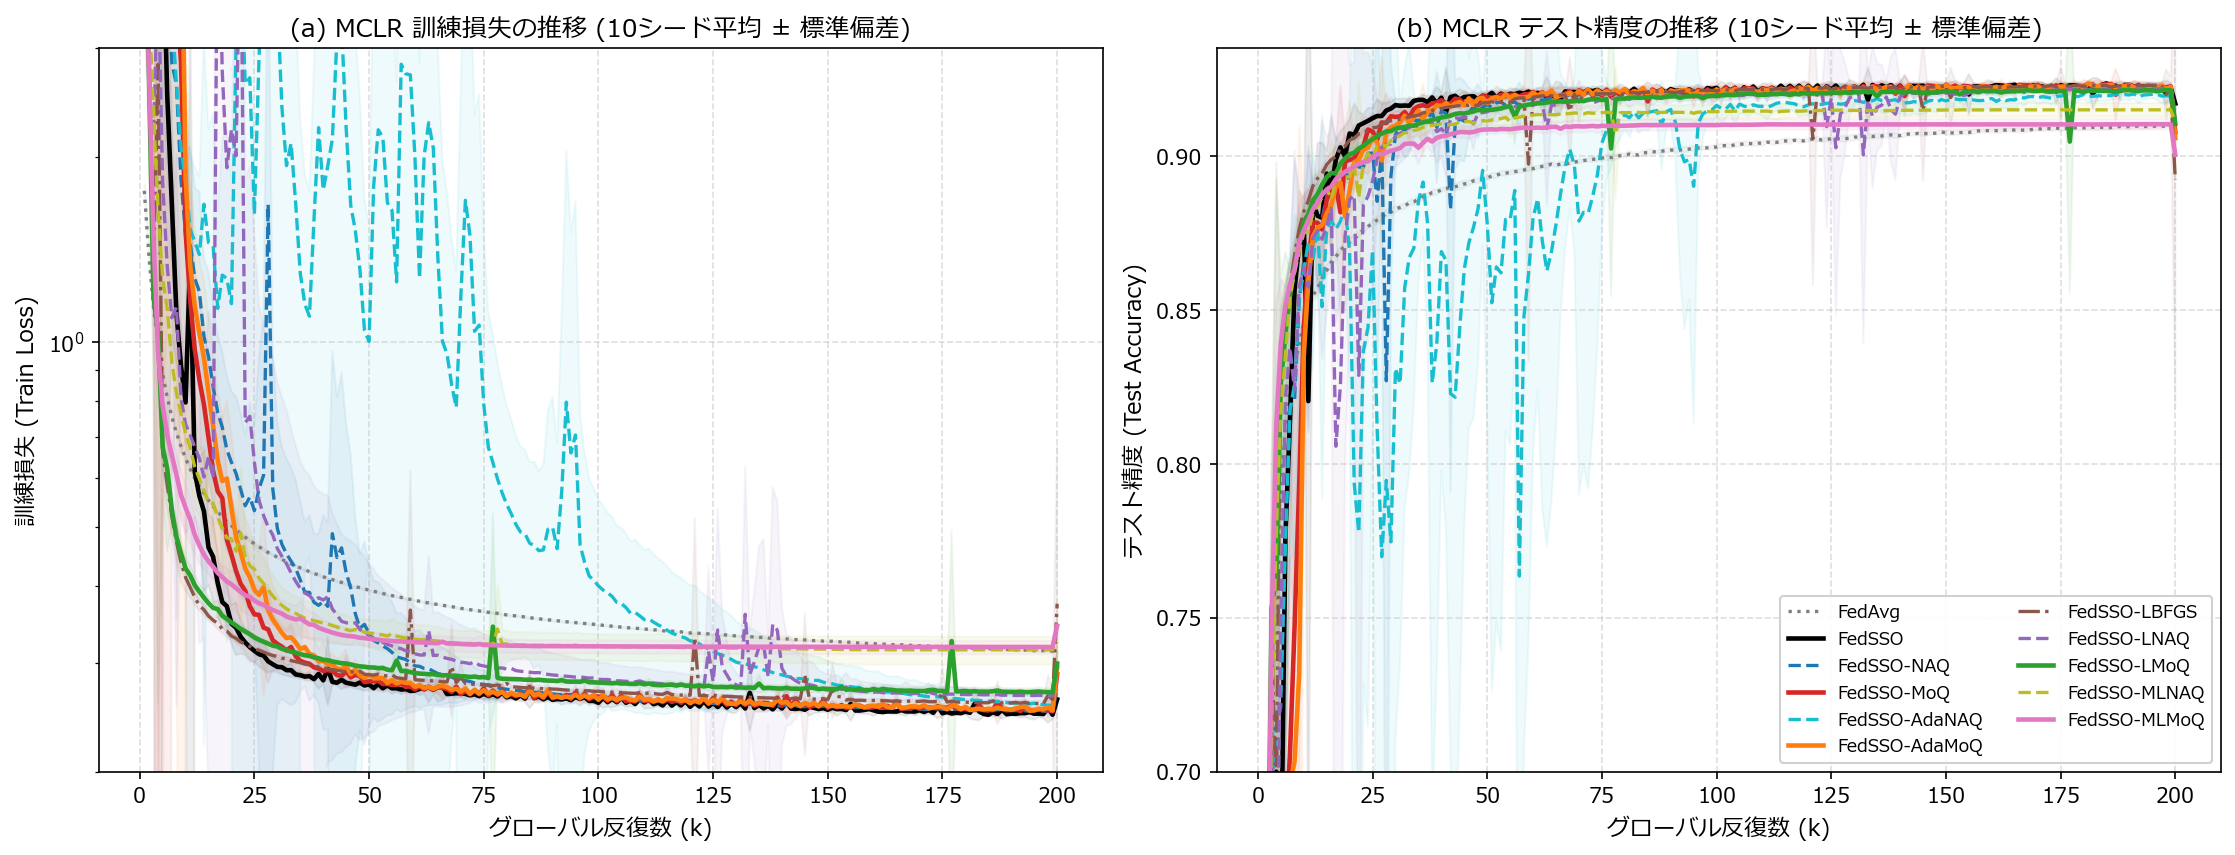

In [5]:
# 図1: MCLR 10シード平均学習曲線 (訓練損失 & テスト精度, 標準偏差帯域付き)
rounds_x = np.arange(1, 201)
color_map = {
    "FedAvg": "#7f7f7f",
    "FedSSO": "#000000",
    "FedSSO-NAQ": "#1f77b4",
    "FedSSO-MoQ": "#d62728",
    "FedSSO-AdaNAQ": "#17becf",
    "FedSSO-AdaMoQ": "#ff7f0e",
    "FedSSO-LBFGS": "#8c564b",
    "FedSSO-LNAQ": "#9467bd",
    "FedSSO-LMoQ": "#2ca02c",
    "FedSSO-MLNAQ": "#bcbd22",
    "FedSSO-MLMoQ": "#e377c2",
}
ls_map = {
    "FedAvg": ":",
    "FedSSO": "-",
    "FedSSO-NAQ": "--",
    "FedSSO-MoQ": "-",
    "FedSSO-AdaNAQ": "--",
    "FedSSO-AdaMoQ": "-",
    "FedSSO-LBFGS": "-.",
    "FedSSO-LNAQ": "--",
    "FedSSO-LMoQ": "-",
    "FedSSO-MLNAQ": "--",
    "FedSSO-MLMoQ": "-",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for name, d_c in curves_dict.items():
    c = color_map[name]
    ls = ls_map[name]
    lw = 2.2 if "MoQ" in name or name == "FedSSO" else 1.6
    axes[0].plot(rounds_x, d_c["loss_mean"], label=name, color=c, linestyle=ls, linewidth=lw)
    axes[0].fill_between(rounds_x, np.maximum(d_c["loss_mean"] - d_c["loss_std"], 1e-4), d_c["loss_mean"] + d_c["loss_std"], color=c, alpha=0.07)
    axes[1].plot(rounds_x, d_c["acc_mean"], label=name, color=c, linestyle=ls, linewidth=lw)
    axes[1].fill_between(rounds_x, d_c["acc_mean"] - d_c["acc_std"], d_c["acc_mean"] + d_c["acc_std"], color=c, alpha=0.07)

axes[0].set_title("(a) MCLR 訓練損失の推移 (10シード平均 ± 標準偏差)", fontsize=12)
axes[0].set_xlabel("グローバル反復数 (k)", fontsize=11)
axes[0].set_ylabel("訓練損失 (Train Loss)", fontsize=11)
axes[0].set_yscale("log")
axes[0].set_ylim(0.20, 3.0)
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].set_title("(b) MCLR テスト精度の推移 (10シード平均 ± 標準偏差)", fontsize=12)
axes[1].set_xlabel("グローバル反復数 (k)", fontsize=11)
axes[1].set_ylabel("テスト精度 (Test Accuracy)", fontsize=11)
axes[1].set_ylim(0.70, 0.935)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="lower right", fontsize=8.5, ncol=2, framealpha=0.92)

plt.tight_layout()
plt.savefig("../report/img/ex001_mclr_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

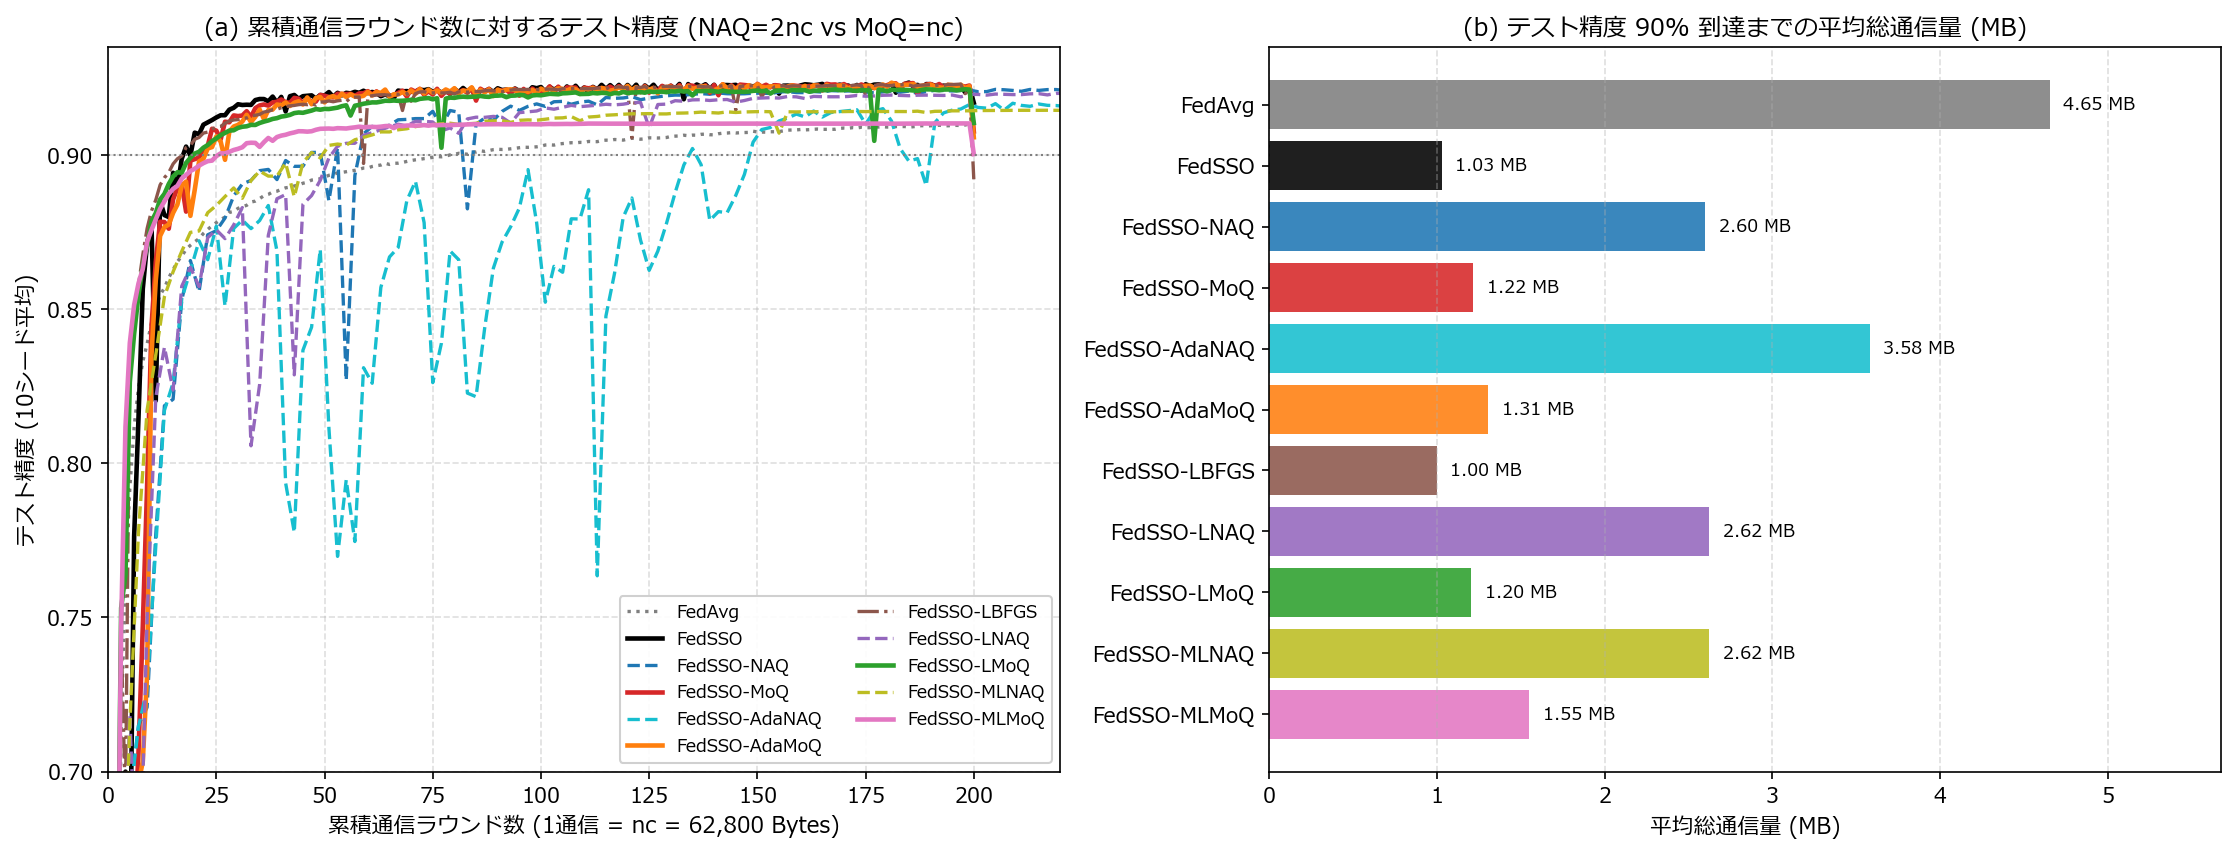

In [6]:
# 図2: 累積通信ラウンド数に対するテスト精度と 90% 到達通信量比較
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for name, d_c in curves_dict.items():
    c = color_map[name]
    ls = ls_map[name]
    lw = 2.2 if "MoQ" in name or name == "FedSSO" else 1.6
    axes[0].plot(d_c["comm_mean"], d_c["acc_mean"], label=name, color=c, linestyle=ls, linewidth=lw)

axes[0].set_title("(a) 累積通信ラウンド数に対するテスト精度 (NAQ=2nc vs MoQ=nc)", fontsize=11.5)
axes[0].set_xlabel("累積通信ラウンド数 (1通信 = nc = 62,800 Bytes)", fontsize=10.5)
axes[0].set_ylabel("テスト精度 (10シード平均)", fontsize=10.5)
axes[0].set_xlim(0, 220)
axes[0].set_ylim(0.70, 0.935)
axes[0].axhline(0.90, color="gray", linestyle=":", linewidth=1.0)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(loc="lower right", fontsize=8.5, ncol=2, framealpha=0.92)

plot_df = summary_df.copy()
plot_df["MB_090"] = plot_df["Bytes@0.90_Ave"] / (1024.0 ** 2)
bars = axes[1].barh(plot_df["Algorithm"][::-1], plot_df["MB_090"][::-1], color=[color_map[a] for a in plot_df["Algorithm"][::-1]], alpha=0.88)
for bar, val in zip(bars, plot_df["MB_090"][::-1]):
    if np.isfinite(val):
        axes[1].text(val + 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.2f} MB", va="center", fontsize=8.5)
axes[1].set_title("(b) テスト精度 90% 到達までの平均総通信量 (MB)", fontsize=11.5)
axes[1].set_xlabel("平均総通信量 (MB)", fontsize=10.5)
axes[1].set_xlim(0, max(plot_df["MB_090"].dropna()) * 1.22)
axes[1].grid(True, axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("../report/img/ex001_mclr_comm_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

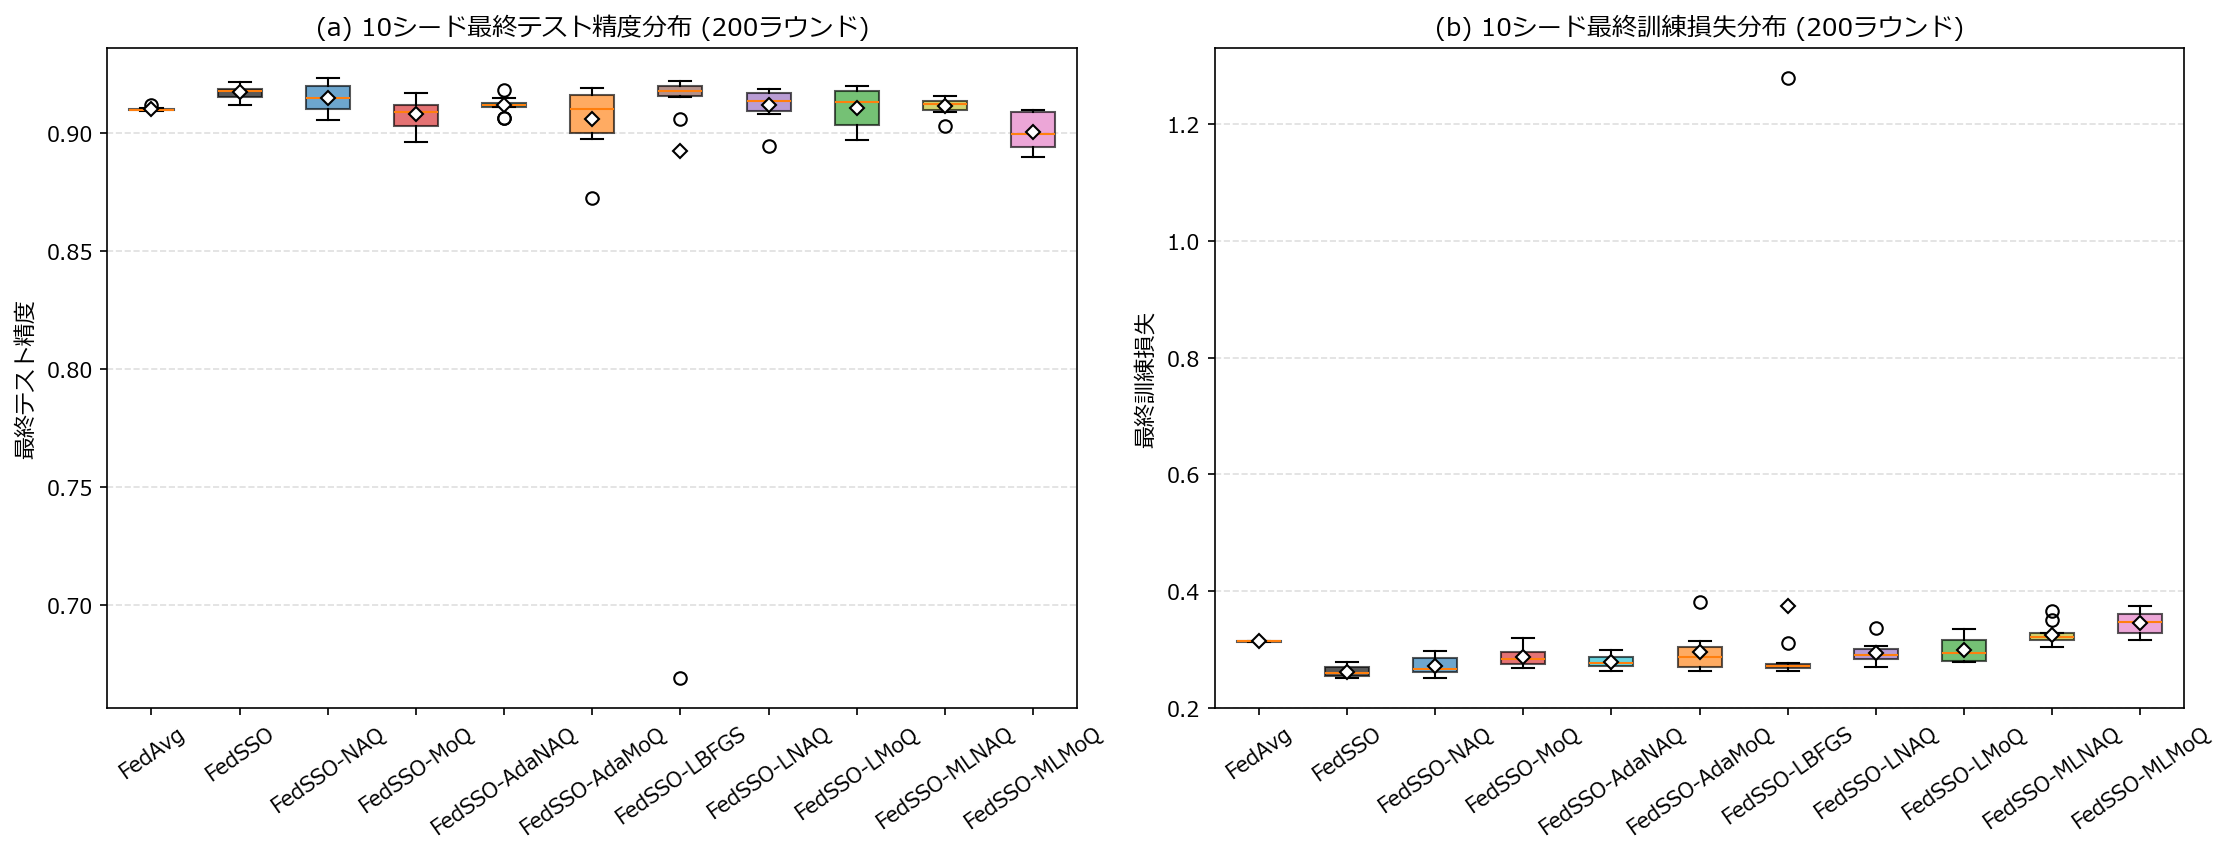

<cell-7>:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
<cell-7>:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


In [7]:
# 図3: 10シードにわたる最終テスト精度と最終訓練損失の分布 (Ave / Best / Worst)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
algos = list(summary_df["Algorithm"])
acc_groups = [per_seed_df[per_seed_df["Algorithm"] == a]["Final_Acc"].values for a in algos]
loss_groups = [per_seed_df[per_seed_df["Algorithm"] == a]["Final_Loss"].values for a in algos]

bp1 = axes[0].boxplot(acc_groups, labels=algos, patch_artist=True, showmeans=True,
                      meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
for patch, a in zip(bp1["boxes"], algos):
    patch.set_facecolor(color_map[a])
    patch.set_alpha(0.65)
axes[0].set_title("(a) 10シード最終テスト精度分布 (200ラウンド)", fontsize=12)
axes[0].set_ylabel("最終テスト精度", fontsize=11)
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

bp2 = axes[1].boxplot(loss_groups, labels=algos, patch_artist=True, showmeans=True,
                      meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
for patch, a in zip(bp2["boxes"], algos):
    patch.set_facecolor(color_map[a])
    patch.set_alpha(0.65)
axes[1].set_title("(b) 10シード最終訓練損失分布 (200ラウンド)", fontsize=12)
axes[1].set_ylabel("最終訓練損失", fontsize=11)
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("../report/img/ex001_mclr_seed_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 特定のシード値・アルゴリズムに絞ったグラフ表示

実験で自動保存されたシード別・アルゴリズム別の全ラウンド推移 CSV（`../datasets/ex001_mclr_history.csv` および `../datasets/ex001_mclr_logs/{Algorithm}_seed{Seed}.csv`）を読み込み、任意のアルゴリズム・シード値だけを指定して学習曲線を再描画できます。

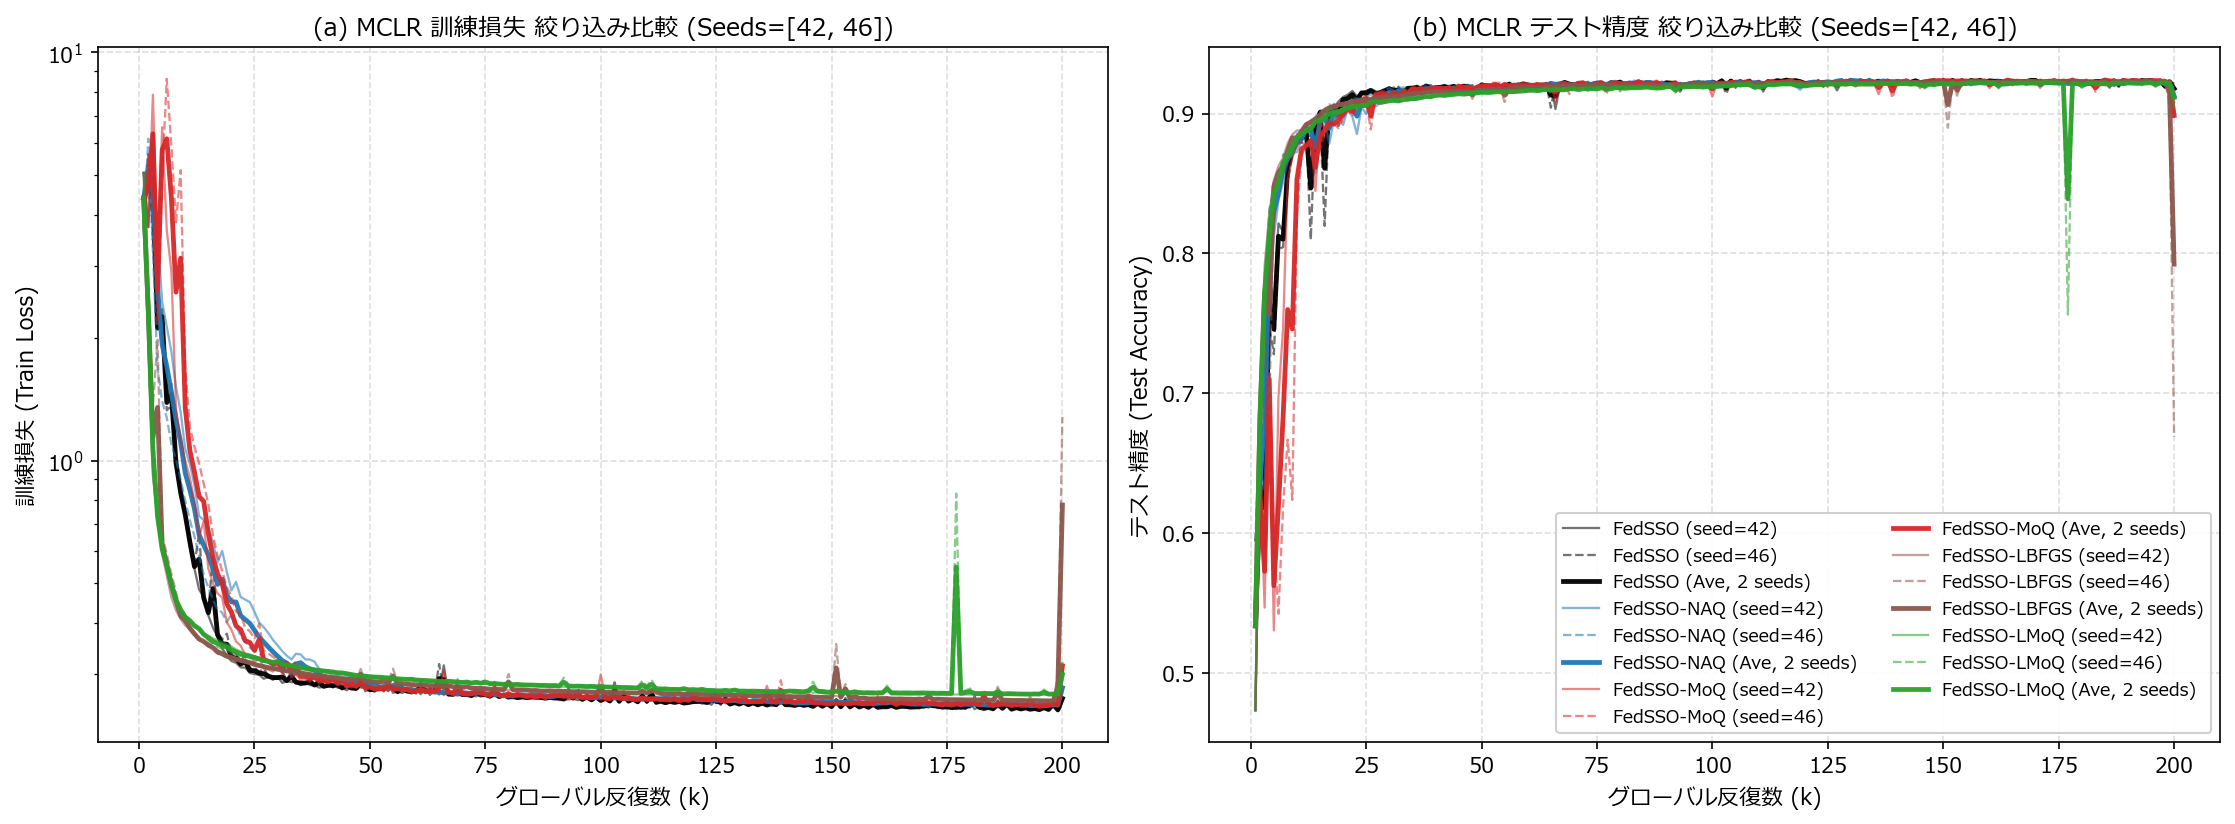

,Algorithm,Seed,Round,Comm_Round,Train_Loss,Test_Acc
0,FedSSO,42,200,200,0.271772,0.914268
1,FedSSO,46,200,200,0.250520,0.921407
2,FedSSO-LBFGS,42,200,200,0.276343,0.915810
3,FedSSO-LBFGS,46,200,200,1.279194,0.668780
4,FedSSO-LMoQ,42,200,200,0.318119,0.904158
5,FedSSO-LMoQ,46,200,200,0.279828,0.918723
6,FedSSO-MoQ,42,200,200,0.307064,0.901302
7,FedSSO-MoQ,46,200,200,0.320396,0.895933
8,FedSSO-NAQ,42,200,399,0.288959,0.908328
9,FedSSO-NAQ,46,200,399,0.265824,0.916895


In [8]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LBFGS", "FedSSO-LMoQ"]
SELECTED_SEEDS = [42, 46]   # 例: [46] にすると LBFGS のシード46 単独比較、None で全10シード
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか

filtered_ex1_df = plot_filtered_mclr_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex001_mclr_history.csv",
    log_dir="../datasets/ex001_mclr_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
)
filtered_ex1_df